<a href="https://colab.research.google.com/github/hinrandy/Hackathon-SwampXII/blob/main/HackathonProject_(1)_(3).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import sklearn



In [ ]:
df = pd.read_csv('student-mat.csv', sep=";")


In [ ]:
df.shape

(395, 33)

In [ ]:
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [ ]:
df.dtypes

,0
school,object
sex,object
age,int64
address,object
famsize,object
Pstatus,object
Medu,int64
Fedu,int64
Mjob,object
Fjob,object


In [ ]:
df.isnull().sum().sum()

np.int64(0)

<Axes: >

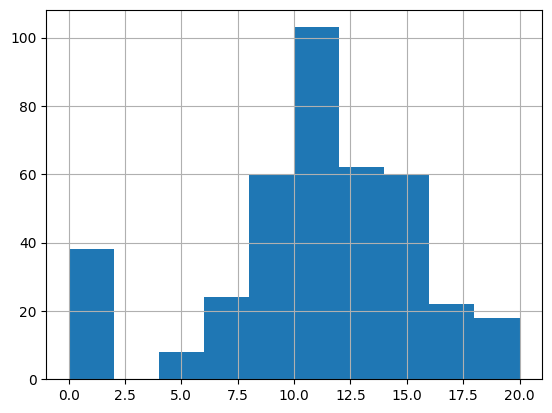

In [ ]:
df['G3'].hist()

In [ ]:
df[df['G3'] == 0][['G1','G2','G3','absences','failures']]

,G1,G2,G3,absences,failures
128,7,4,0,0,2
130,12,0,0,0,2
131,8,0,0,0,0
134,9,0,0,0,0
135,11,0,0,0,0
136,10,0,0,0,0
137,4,0,0,0,2
140,7,9,0,0,0
144,5,0,0,0,3
146,6,7,0,0,3


In [ ]:
df_clean = df[df['G3'] != 0]

In [ ]:
df_clean.shape

(357, 33)

In [ ]:
(df['G3'] == 0).sum()

np.int64(38)

<Axes: >

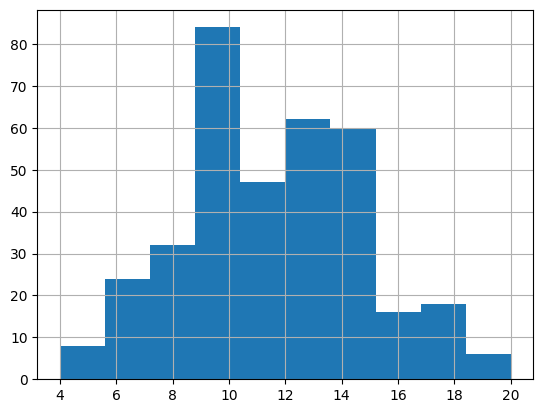

In [ ]:
df_clean['G3'].hist()

In [ ]:
df_clean.columns

Index(['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu',
       'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime',
       'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery',
       'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc',
       'Walc', 'health', 'absences', 'G1', 'G2', 'G3'],
      dtype='object')

In [ ]:
df.columns

Index(['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu',
       'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime',
       'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery',
       'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc',
       'Walc', 'health', 'absences', 'G1', 'G2', 'G3'],
      dtype='object')

In [ ]:
# Create the 'passed' column (assuming a passing grade is >= 10)
df['passed'] = df['G3'] >= 10

# Now we can safely display both columns
df[['G3', 'passed']].head(10)

,G3,passed
0,6,False
1,6,False
2,10,True
3,15,True
4,10,True
5,15,True
6,11,True
7,6,False
8,19,True
9,15,True


In [ ]:
# Drop the column safely; if it doesn't exist, ignore the error
df_clean = df.drop(columns='passed', errors='ignore')

In [ ]:
df_clean.shape

(395, 33)

In [ ]:
df_clean[['studytime', 'freetime']].corr()

,studytime,freetime
studytime,1.000000,-0.143198
freetime,-0.143198,1.000000


In [ ]:
%%writefile app.py
import base64
from pathlib import Path

import joblib
import pandas as pd
import streamlit as st
import streamlit.components.v1 as components

# ---------------------------------------------------------------------------
# SETTINGS
# ---------------------------------------------------------------------------
MODEL_PATH = Path(__file__).parent / "model.pkl"
FEATURE_COLUMNS = ["studytime", "absences", "G1"]  # must match training order
PASS_MARK = 10  # G3 >= 10 counts as passing

PASS_COLOR = "#2f8f5b"  # circle colour when the student is on track
FAIL_COLOR = "#d64545"  # circle colour when the student is at risk

# Where the title + subtitle go:
#   True  -> inside the left column, above the input card. This matches the
#            mockup: the output card starts at the top of the page next to the
#            title, and both cards end on the same bottom line.
#   False -> across the whole top of the page, so both cards start on the same
#            line AND end on the same line (two equal boxes side by side).
HEADER_IN_LEFT_COLUMN = True

st.set_page_config(
    page_title="Grade Predictor",
    layout="wide",
    initial_sidebar_state="collapsed",
)


# ---------------------------------------------------------------------------
# HELPER: render raw HTML without it turning into a code block
#
# Streamlit runs st.markdown() through a Markdown parser. Any line indented by
# 4+ spaces (or any blank line inside a <div>) makes it show your HTML as plain
# text. Stripping each line's indentation and joining into one line avoids it.
# ---------------------------------------------------------------------------
def html(block: str) -> None:
    flat = " ".join(line.strip() for line in block.strip().splitlines() if line.strip())
    st.markdown(flat, unsafe_allow_html=True)


# ---------------------------------------------------------------------------
# CSS  (colours sampled from the mockup)
# ---------------------------------------------------------------------------
CSS = """
@import url('https://fonts.googleapis.com/css2?family=Finger+Paint&family=Press+Start+2P&display=swap');

/* ===== GLOBAL PAGE ===== */
.stApp {
    background: linear-gradient(180deg,
        #cbfbb9 0%, #91cca0 21%, #539682 45%, #366a5b 68%, #214130 91%, #1b3424 100%);
    color: #000;
    font-family: "Comic Sans MS", "Chalkboard SE", sans-serif;
}
header[data-testid="stHeader"] { background: transparent; }
.block-container, [data-testid="stMainBlockContainer"] {
    max-width: 100%;
    padding: 1.25rem 2.5rem 2rem 2.5rem;
}

/* ===== TITLE + SUBTITLE ===== */
.header-title {
    font-family: "Press Start 2P", "Brick Sans", Impact, sans-serif;
    font-size: clamp(16px, 2.2vw, 48px);
    line-height: 1.3;
    letter-spacing: 0;
    color: #000;
    margin: 0;
}
.header-subtitle {
    background: #326f51;
    color: #d9d9d9;
    border-radius: 22px;
    padding: 14px 20px;
    max-width: 760px;
    text-align: center;
    font-family: "Comic Sans MS", "Chalkboard SE", sans-serif;
    font-size: clamp(14px, 1.5vw, 24px);
    line-height: 1.35;
    font-weight: 600;
    margin: 0;
}

/* ===== LAYOUT: equal-height columns, each card fills its column =====
   The two cards end on the same line because each one stretches to the
   bottom of its column, and both columns are the same height. */
div[data-testid="stHorizontalBlock"] { align-items: stretch !important; }

div[data-testid="stColumn"]:has(.st-key-input-card),
div[data-testid="stColumn"]:has(.st-key-output-card),
div[data-testid="column"]:has(.st-key-input-card),
div[data-testid="column"]:has(.st-key-output-card) {
    display: flex !important;
    flex-direction: column !important;
}
div[data-testid="stColumn"]:has(.st-key-input-card) > div,
div[data-testid="stColumn"]:has(.st-key-output-card) > div,
div[data-testid="column"]:has(.st-key-input-card) > div,
div[data-testid="column"]:has(.st-key-output-card) > div {
    flex: 1 1 auto !important;
}
/* Newer Streamlit wraps containers in an extra div; take it out of the layout */
div[data-testid="stColumn"]:has(.st-key-input-card) [data-testid="stLayoutWrapper"],
div[data-testid="stColumn"]:has(.st-key-output-card) [data-testid="stLayoutWrapper"] {
    display: contents !important;
}

/* ===== INPUT CARD ===== */
.st-key-input-card {
    flex: 1 1 auto !important;
    background: linear-gradient(180deg,
        #b8e4f9 0%, #a4c8e9 13%, #859cd3 27%, #5f64b8 45%,
        #40438e 63%, #232a5f 81%, #071130 100%);
    border: 4px solid #fff;
    border-radius: 40px;
    padding: 0 26px 24px 26px;
    box-sizing: border-box;
}
.section-heading {
    width: 84%;
    margin: 0 auto 8px auto;
    box-sizing: border-box;
    background: #fff;
    color: #545454;
    border-radius: 0 0 36px 36px;
    padding: 14px 18px 16px 18px;
    text-align: center;
    text-transform: uppercase;
    letter-spacing: 0.2em;
    font-family: "Finger Paint", cursive;
    font-size: clamp(18px, 1.9vw, 32px);
}

/* Labels */
.st-key-input-card [data-testid="stWidgetLabel"],
.st-key-input-card [data-testid="stWidgetLabel"] p,
.st-key-input-card [data-testid="stWidgetLabel"] label {
    color: #fff !important;
    font-size: 15px !important;
    font-weight: 500 !important;
}

/* Number inputs: white pill, dark text and +/- */
.st-key-input-card [data-testid="stNumberInput"] { background: transparent !important; }
.st-key-input-card [data-testid="stNumberInput"] [data-baseweb="input"] {
    background: #fff !important;
    border: none !important;
    border-radius: 999px !important;
    box-shadow: none !important;
    overflow: hidden !important;
    min-height: 46px;
}
.st-key-input-card [data-testid="stNumberInput"] [data-baseweb="input"] > div,
.st-key-input-card [data-testid="stNumberInput"] [data-baseweb="base-input"] {
    background: #fff !important;
    border: none !important;
    box-shadow: none !important;
}
.st-key-input-card [data-testid="stNumberInput"] input {
    background: #fff !important;
    color: #111 !important;
    -webkit-text-fill-color: #111 !important;
    caret-color: #111 !important;
    border: none !important;
    box-shadow: none !important;
    outline: none !important;
    padding-left: 20px !important;
}
.st-key-input-card [data-testid="stNumberInput"] button {
    background: #fff !important;
    color: #111 !important;
    border: none !important;
    box-shadow: none !important;
    outline: none !important;
}
.st-key-input-card [data-testid="stNumberInput"] button svg {
    color: #111 !important; fill: #111 !important; stroke: #111 !important;
}
.st-key-input-card [data-testid="stNumberInput"] button:hover { background: #eee !important; }

/* Dropdown: white pill, dark text and arrow */
.st-key-input-card [data-testid="stSelectbox"] [data-baseweb="select"] > div {
    background: #fff !important;
    border: none !important;
    border-radius: 999px !important;
    box-shadow: none !important;
    min-height: 46px;
}
.st-key-input-card [data-testid="stSelectbox"] [data-baseweb="select"] > div > div {
    background: transparent !important;
}
.st-key-input-card [data-testid="stSelectbox"] [data-baseweb="select"] span {
    color: #111 !important; -webkit-text-fill-color: #111 !important;
}
.st-key-input-card [data-testid="stSelectbox"] [data-baseweb="select"] svg {
    color: #111 !important; fill: #111 !important; stroke: #111 !important;
}
div[data-baseweb="popover"] ul[role="listbox"],
div[data-baseweb="popover"] li[role="option"] {
    background: #fff !important; color: #111 !important;
}
div[data-baseweb="popover"] li[role="option"] * {
    color: #111 !important; -webkit-text-fill-color: #111 !important;
}
div[data-baseweb="popover"] li[role="option"]:hover { background: #eee !important; }

/* ===== OUTPUT CARD ===== */
.st-key-output-card {
    flex: 1 1 auto !important;
    background: #2f6569;
    border: 4px solid #fff;
    border-radius: 40px;
    padding: 22px;
    box-sizing: border-box;
}
/* Inside the output card, drop Streamlit's wrapper divs so the pill, circle and
   outline box become direct flex children and can stretch to fill the card */
.st-key-output-card [data-testid="stElementContainer"],
.st-key-output-card [data-testid="element-container"],
.st-key-output-card [data-testid="stMarkdown"],
.st-key-output-card [data-testid="stMarkdownContainer"] {
    display: contents !important;
}
.st-key-output-card [data-testid="stHorizontalBlock"] { flex: 1 1 auto !important; }
.st-key-output-card [data-testid="stColumn"],
.st-key-output-card [data-testid="column"] {
    display: flex !important;
    flex-direction: column !important;
}
.st-key-output-card [data-testid="stColumn"] > div,
.st-key-output-card [data-testid="column"] > div { flex: 1 1 auto !important; }

.predicted-output-pill {
    width: 100%;
    box-sizing: border-box;
    background: #56bc6c;
    border: 4px solid #fff;
    border-radius: 999px;
    padding: 14px 18px;
    text-align: center;
    text-transform: uppercase;
    letter-spacing: 0.12em;
    line-height: 1.2;
    color: #d9d9d9;
    font-family: "Finger Paint", cursive;
    font-size: clamp(20px, 2.8vw, 46px);
}

/* PASS / FAIL circle */
.circle-status {
    width: min(100%, 300px);
    aspect-ratio: 1 / 1;
    box-sizing: border-box;
    margin: 14px auto 0 auto;
    border: 4px solid #fff;
    border-radius: 50%;
    display: flex;
    flex-direction: column;
    align-items: center;
    justify-content: center;
    text-align: center;
    color: #fff;
    font-family: Arial, sans-serif;
    font-size: clamp(18px, 1.9vw, 30px);
    font-weight: 800;
}
.circle-probability { font-size: clamp(14px, 1.2vw, 18px); font-weight: 600; margin-top: 4px; }
.circle-caption { font-size: 12px; font-weight: 400; margin-top: 2px; opacity: 0.9; }

/* Big outline box */
.gemini-outline-box {
    flex: 1 1 auto;
    width: 100%;
    min-height: 420px;
    box-sizing: border-box;
    background: #326f51;
    border: 4px solid #fff;
    border-radius: 40px;
    padding: 18px 24px 24px 24px;
    color: #f5f5f5;
}
.gemini-title {
    display: block;
    width: fit-content;
    max-width: 100%;
    box-sizing: border-box;
    margin: 0 auto 16px auto;
    background: #3c6324;
    border: 4px solid #fff;
    border-radius: 999px;
    padding: 8px 36px;
    text-align: center;
    color: #d9d9d9;
    font-family: "Finger Paint", cursive;
    font-size: clamp(20px, 2.3vw, 38px);
}
.prediction-details {
    font-family: Arial, sans-serif;
    font-size: 14px;
    line-height: 1.6;
    color: #f5f5f5;
    margin-top: 12px;
}
.prediction-details p { margin: 0 0 16px 0; }

/* Demo-mode notice */
.demo-banner {
    background: #fff3cd;
    color: #5c4400;
    border-radius: 20px;
    padding: 10px 18px;
    font-family: Arial, sans-serif;
    font-size: 14px;
}

/* ===== RESPONSIVE ===== */
@media (max-width: 900px) {
    .block-container, [data-testid="stMainBlockContainer"] { padding: 1rem 1rem 2rem 1rem; }
    .st-key-input-card, .st-key-output-card { min-height: auto !important; }
    .st-key-output-card { padding: 16px; }
    .circle-status { width: 160px; }
    .gemini-outline-box { min-height: 300px; border-radius: 30px; }
}
"""
html(f"<style>{CSS}</style>")

# Fallback heights: only used if a card's content is shorter than this.
# (The cards normally stretch to match each other on their own.)
INPUT_MIN_H, OUTPUT_MIN_H = (560, 760) if HEADER_IN_LEFT_COLUMN else (680, 680)
html(
    f"<style>.st-key-input-card {{ min-height: {INPUT_MIN_H}px; }} "
    f".st-key-output-card {{ min-height: {OUTPUT_MIN_H}px; }}</style>"
)

# Sound on/off (open the small arrow at the top-left to find it)
sound_on = st.sidebar.toggle("Sound effects", value=True)


# ---------------------------------------------------------------------------
# LOAD MODEL (joblib.load also reads plain pickle files)
# ---------------------------------------------------------------------------
@st.cache_resource
def load_model():
    try:
        return joblib.load(MODEL_PATH), None
    except Exception as exc:  # missing file, version mismatch, corrupt file...
        return None, f"{type(exc).__name__}: {exc}"


model, load_error = load_model()


# ---------------------------------------------------------------------------
# HEADER
# ---------------------------------------------------------------------------
def render_header() -> None:
    html('<div class="header-title">Grade Predictor</div>')
    html(
        """
        <div class="header-subtitle">
            Enter your early-semester metrics and test how changing your
            study habits impacts your final grade.
        </div>
        """
    )


if not HEADER_IN_LEFT_COLUMN:
    render_header()

# ---------------------------------------------------------------------------
# MAIN LAYOUT
# ---------------------------------------------------------------------------
left_col, right_col = st.columns([0.9, 1.4], gap="large")

# LEFT: (HEADER) + INPUT CARD
with left_col:
    if HEADER_IN_LEFT_COLUMN:
        render_header()

    with st.container(key="input-card"):
        html('<div class="section-heading">Input Metrics</div>')

        studytime = st.number_input(
            "Weekly Hours Studied (1: <2h, 2: 2-5h, 3: 5-10h, 4: >10h):",
            min_value=1, max_value=4, value=2, step=1,
        )
        g1 = st.number_input(
            "Grades (G1 - First Period Grade 0-20):",
            min_value=0, max_value=20, value=12, step=1,
        )
        # NOT used by the model yet. Wire these into the "honesty layer"
        # (weighted assignment average) before feeding the model.
        completion_method = st.selectbox(
            "Method of Completion:",
            options=["Standard", "Self-Study", "Group Study", "Tutoring"],
        )
        assignment_grade = st.number_input(
            "Assignment Grade (0-100%):",
            min_value=0, max_value=100, value=85, step=5,
        )
        absences = st.number_input(
            "Absences:",
            min_value=0, max_value=93, value=4, step=1,
        )

# ---------------------------------------------------------------------------
# PREDICTION
# ---------------------------------------------------------------------------
demo_mode = model is None
headline_value = ""   # big text inside the circle
caption = ""          # small label under it
detail_line = ""      # bullet in the outline box

if not demo_mode:
    try:
        X = pd.DataFrame([[studytime, absences, g1]], columns=FEATURE_COLUMNS)
        if hasattr(model, "predict_proba"):
            # Classifier: probability of the "passed" class
            prob = float(model.predict_proba(X)[0][1]) * 100
            passed = prob >= 50
            headline_value = f"{prob:.0f}%"
            caption = "pass probability"
            detail_line = f"Current Pass Probability: <b>{prob:.1f}%</b>"
        else:
            # Regressor: predicts the final grade (G3) directly
            grade = float(model.predict(X)[0])
            passed = grade >= PASS_MARK
            headline_value = f"{grade:.1f}/20"
            caption = "predicted final grade"
            detail_line = f"Predicted Final Grade: <b>{grade:.1f}/20</b>"
    except Exception as exc:
        load_error = f"Model loaded but prediction failed: {type(exc).__name__}: {exc}"
        demo_mode = True

if demo_mode:
    # Rule-of-thumb stand-in so the UI still works. NOT a trained model.
    passed = g1 >= PASS_MARK and absences < 10
    prob = min(95.0, max(15.0, (g1 * 4) + (studytime * 5) - (absences * 2)))
    headline_value = f"{prob:.0f}%"
    caption = "rough estimate"
    detail_line = f"Rough Estimate: <b>{prob:.1f}%</b>"

badge_color = PASS_COLOR if passed else FAIL_COLOR
badge_text = "PASS" if passed else "FAIL"

if passed:
    status_line = "✅ <b>On Track to Pass!</b>"
    advice = (
        f"Your G1 score of <b>{g1}/20</b> and absence count "
        f"(<b>{absences}</b>) contribute to your prediction."
    )
else:
    status_line = "⚠️ <b>Risk of Failing</b>"
    advice = (
        "Consider increasing study time and reducing absences "
        "to improve your academic performance."
    )

# RIGHT: OUTPUT CARD
with right_col:
    with st.container(key="output-card"):
        if demo_mode:
            reason = load_error or "model.pkl was not found next to app.py"
            html(
                f"""
                <div class="demo-banner">
                    <b>Demo mode:</b> showing a rule-of-thumb estimate, not the
                    trained model. ({reason})
                </div>
                """
            )

        html('<div class="predicted-output-pill">Predicted Output</div>')

        circle_col, outline_col = st.columns([0.4, 1], gap="small")

        with circle_col:
            html(
                f"""
                <div class="circle-status" style="background-color: {badge_color};">
                    <div>{badge_text}</div>
                    <div class="circle-probability">{headline_value}</div>
                    <div class="circle-caption">{caption}</div>
                </div>
                """
            )

        with outline_col:
            html(
                f"""
                <div class="gemini-outline-box">
                    <div class="gemini-title">Gemini outline</div>
                    <div class="prediction-details">
                        <p>{status_line}</p>
                        <p>• {detail_line}</p>
                        <p>• {advice}</p>
                    </div>
                </div>
                """
            )


# ---------------------------------------------------------------------------
# SOUND EFFECTS (keep this at the END of the file)
#
# Put click.mp3 in the same folder as app.py. If it is missing, the app falls
# back to a synthesized beep, so nothing breaks.
#
# Streamlit strips <script> tags from st.markdown, so the script rides in on a
# zero-height component. It copies one function into the real page, where it
# listens for clicks on the number inputs' +/- buttons (and the Up/Down arrow
# keys). The clip is decoded once and played with the Web Audio API, which
# allows instant playback and rapid overlapping clicks.
# ---------------------------------------------------------------------------
SOUND_FILE = Path(__file__).parent / "click.mp3"


@st.cache_resource
def load_click_sound() -> str:
    try:
        return base64.b64encode(SOUND_FILE.read_bytes()).decode()
    except OSError:
        return ""  # no file -> JS uses the synthesized beep


SOUND_JS = """
<script>
(function () {
  const P = window.parent;
  P.__gpSoundOn = __SOUND_ON__;          // updated on every rerun (the toggle)
  P.__gpSoundB64 = "__SOUND_B64__";      // base64 of click.mp3 ("" if missing)
  if (P.__gpSoundsInstalled) return;     // only attach listeners once
  P.__gpSoundsInstalled = true;

  function sounds() {
    const UP_RATE = 1.15;    // + plays the clip slightly higher/faster
    const DOWN_RATE = 0.85;  // - plays it slightly lower/slower
    const VOLUME = 0.9;

    const AC = window.AudioContext || window.webkitAudioContext;
    const ctx = new AC();    // starts "suspended"; resumed on the first click
    let buffer = null;

    // Decode the clip once, up front
    if (window.__gpSoundB64) {
      try {
        const bin = atob(window.__gpSoundB64);
        const bytes = new Uint8Array(bin.length);
        for (let i = 0; i < bin.length; i++) bytes[i] = bin.charCodeAt(i);
        ctx.decodeAudioData(bytes.buffer).then(function (b) { buffer = b; }).catch(function () {});
      } catch (err) {}
    }

    function sample(rate) {
      const src = ctx.createBufferSource();
      const gain = ctx.createGain();
      src.buffer = buffer;
      src.playbackRate.value = rate;
      gain.gain.value = VOLUME;
      src.connect(gain);
      gain.connect(ctx.destination);
      src.start();
    }

    // Fallback beep (used if click.mp3 is missing or still decoding)
    function beep(from, to) {
      const t = ctx.currentTime;
      const osc = ctx.createOscillator();
      const gain = ctx.createGain();
      osc.type = "triangle";
      osc.frequency.setValueAtTime(from, t);
      osc.frequency.exponentialRampToValueAtTime(to, t + 0.09);
      gain.gain.setValueAtTime(0.0001, t);
      gain.gain.exponentialRampToValueAtTime(0.25, t + 0.01);
      gain.gain.exponentialRampToValueAtTime(0.0001, t + 0.12);
      osc.connect(gain);
      gain.connect(ctx.destination);
      osc.start(t);
      osc.stop(t + 0.13);
    }

    function play(rate, from, to) {
      if (!window.__gpSoundOn) return;
      if (ctx.state === "suspended") ctx.resume();
      buffer ? sample(rate) : beep(from, to);
    }
    const up = () => play(UP_RATE, 520, 820);
    const down = () => play(DOWN_RATE, 520, 330);

    // Delegated listeners survive Streamlit re-rendering the widgets.
    document.addEventListener("click", function (e) {
      const btn = e.target.closest && e.target.closest('[data-testid="stNumberInput"] button');
      if (!btn) return;
      const id = (btn.getAttribute("data-testid") || "").toLowerCase();
      const cls = String(btn.className || "").toLowerCase();
      if (id.includes("stepup") || cls.includes("step-up")) return up();
      if (id.includes("stepdown") || cls.includes("step-down")) return down();
      // Fallback for other Streamlit versions: first button is -, second is +
      const all = Array.from(btn.parentElement.querySelectorAll("button"));
      all.indexOf(btn) === 0 ? down() : up();
    }, true);

    document.addEventListener("keydown", function (e) {
      if (e.key !== "ArrowUp" && e.key !== "ArrowDown") return;
      if (!e.target.closest || !e.target.closest('[data-testid="stNumberInput"]')) return;
      e.key === "ArrowUp" ? up() : down();
    }, true);
  }

  const s = P.document.createElement("script");
  s.textContent = "(" + sounds.toString() + ")();";
  P.document.head.appendChild(s);
})();
</script>
"""

components.html(
    SOUND_JS.replace("__SOUND_ON__", "true" if sound_on else "false")
    .replace("__SOUND_B64__", load_click_sound()),
    height=0,
)

Overwriting app.py


In [ ]:
%%bash
pip install -q streamlit
npm install -q -g localtunnel


changed 22 packages in 2s

3 packages are looking for funding
  run `npm fund` for details


In [ ]:
# Get the external IP address. This acts as your localtunnel password
print("Your public IP address (Copy this to bypass the localtunnel landing page security check):")
!curl ipv4.icanhazip.com

Your public IP address (Copy this to bypass the localtunnel landing page security check):
34.73.123.152


In [ ]:
# Run Streamlit in the background and expose it via Localtunnel
get_ipython().system_raw('streamlit run app.py & npx localtunnel --port 8501 &')

In [ ]:
# Run Streamlit and expose it via your custom subdomain in the background
get_ipython().system_raw('streamlit run app.py & npx localtunnel --port 8501 --subdomain my-grade-predictor-app &')

In [ ]:
# Check if localtunnel background processes are active
!ps aux | grep localtunnel

root       60665 14.2  0.2 723588 30464 ?        Rl   22:33   0:00 node /tools/node/bin/npx localtunnel --port 8501
root       60668  0.0  0.2 722120 29116 ?        Rl   22:33   0:00 node /tools/node/bin/npx localtunnel --port 8501 --subdomain my-grade-predictor-app
root       60670  0.0  0.0   7344  3612 ?        S    22:33   0:00 /bin/bash -c ps aux | grep localtunnel
root       60676  0.0  0.0   6548  2344 ?        S    22:33   0:00 grep localtunnel


In [ ]:
# Clean up all existing background processes to prepare for relaunch
!pkill -f localtunnel
!pkill -f streamlit
!pkill -f ngrok

In [ ]:
# Install pyngrok to establish a highly reliable tunnel
!pip install -q pyngrok

In [ ]:
import os

# Configure Streamlit to disable strict CORS/Websocket checks which can block asset loading
os.makedirs(os.path.expanduser("~/.streamlit"), exist_ok=True)
with open(os.path.expanduser("~/.streamlit/config.toml"), "w") as f:
    f.write("""[server]
port = 8501
enableCORS = false
enableXsrfProtection = false
""")

# Run Streamlit in the background with updated layout
get_ipython().system_raw("streamlit run app.py --server.port 8501 --server.address 127.0.0.1 &")

In [ ]:
# Start localtunnel and map it directly
get_ipython().system_raw("npx localtunnel --port 8501 --local-host 127.0.0.1 --subdomain my-grade-predictor-app &")

print("Your stable presentation link has been reactivated with layout fixes!")
print("URL: https://my-grade-predictor-app.loca.lt")
print("Password (IP): 34.24.245.76")

Your stable presentation link has been reactivated with layout fixes!
URL: https://my-grade-predictor-app.loca.lt
Password (IP): 34.24.245.76


In [ ]:
# ---------------------------------------------------------------------------
# COLAB LAUNCH CELL
# Run this after app.py (and model.pkl) exist in the Colab file browser.
# Replaces the localtunnel cells. Re-run it any time you edit app.py.
# ---------------------------------------------------------------------------
import os
import re
import subprocess
import sys
import time
import urllib.request

PORT = 8501

# 0. Stop leftovers from earlier runs. Duplicate Streamlit/tunnel processes
#    fighting over the same port or subdomain are a classic cause of
#    "502 Bad Gateway".
for pattern in ["streamlit run", "cloudflared", "localtunnel", "ngrok"]:
    subprocess.run(["pkill", "-f", pattern], check=False)
time.sleep(2)

# 1. Dependencies
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "streamlit", "joblib"], check=True)

if not os.path.exists("app.py"):
    raise FileNotFoundError("app.py not found. Upload it or create it with %%writefile app.py")
if not os.path.exists("model.pkl"):
    print("WARNING: model.pkl not found. The app will run in demo mode (rule-of-thumb numbers).")

# 2. cloudflared: free quick tunnel, no account, no password page
if not os.path.exists("cloudflared"):
    subprocess.run(
        ["wget", "-q",
         "https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64",
         "-O", "cloudflared"],
        check=True,
    )
    os.chmod("cloudflared", 0o755)

# 3. Start Streamlit and WAIT until it answers, so the tunnel never points at nothing
streamlit_log = open("streamlit.log", "w")
subprocess.Popen(
    ["streamlit", "run", "app.py",
     "--server.port", str(PORT),
     "--server.address", "127.0.0.1",
     "--server.headless", "true",
     "--server.enableCORS", "false",
     "--server.enableXsrfProtection", "false",
     "--theme.base", "light"],
    stdout=streamlit_log, stderr=subprocess.STDOUT,
)

for _ in range(60):
    try:
        urllib.request.urlopen(f"http://127.0.0.1:{PORT}/_stcore/health", timeout=1)
        break
    except Exception:
        time.sleep(1)
else:
    print(open("streamlit.log").read())
    raise RuntimeError("Streamlit did not start. Log printed above.")

# 4. Open the tunnel and read the public URL from its log
tunnel_log = open("cloudflared.log", "w")
subprocess.Popen(
    ["./cloudflared", "tunnel", "--url", f"http://127.0.0.1:{PORT}", "--no-autoupdate"],
    stdout=tunnel_log, stderr=subprocess.STDOUT,
)

public_url = None
for _ in range(45):
    match = re.search(r"https://[-a-z0-9]+\.trycloudflare\.com", open("cloudflared.log").read())
    if match:
        public_url = match.group(0)
        break
    time.sleep(1)

if public_url:
    print("Your app is live:", public_url)
    print("If it doesn't load right away, wait ~10 seconds and refresh (new links take a moment).")
else:
    print(open("cloudflared.log").read())
    raise RuntimeError("Tunnel did not start. Log printed above.")

Your app is live: https://marker-dom-whilst-changing.trycloudflare.com
If it doesn't load right away, wait ~10 seconds and refresh (new links take a moment).
